In [1]:
# 1. IMPORT LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)

sns.set_theme(style='whitegrid', palette='Set2')
RANDOM_STATE = 42

In [2]:
# 2. LOAD THE REAL-LIFE DATASET
# The official UCI CSV is loaded directly. You can also download it and
# replace DATA_URL with 'data.csv' to run completely offline.
DATA_URL = 'https://archive.ics.uci.edu/static/public/17/data.csv'
df = pd.read_csv(DATA_URL)

print('Dataset shape:', df.shape)
display(df.head())

Dataset shape: (569, 32)


,ID,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,...,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Diagnosis
0,842302,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,M
1,842517,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,M
2,84300903,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,M
3,84348301,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,M
4,84358402,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,M


In [3]:
# 3. INSPECT DATA QUALITY
print('Column data types:\n', df.dtypes.value_counts())
print('\nMissing values:', int(df.isna().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()))
print('\nOriginal class counts:\n', df['Diagnosis'].value_counts())
display(df.describe().T.head(10))

Column data types:
 float64    30
int64       1
object      1
Name: count, dtype: int64

Missing values: 0
Duplicate rows: 0

Original class counts:
 Diagnosis
B    357
M    212
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
ID,569.0,3.037183e+07,1.250206e+08,8670.00000,869218.00000,906024.00000,8.813129e+06,9.113205e+08
radius1,569.0,1.412729e+01,3.524049e+00,6.98100,11.70000,13.37000,1.578000e+01,2.811000e+01
texture1,569.0,1.928965e+01,4.301036e+00,9.71000,16.17000,18.84000,2.180000e+01,3.928000e+01
perimeter1,569.0,9.196903e+01,2.429898e+01,43.79000,75.17000,86.24000,1.041000e+02,1.885000e+02
area1,569.0,6.548891e+02,3.519141e+02,143.50000,420.30000,551.10000,7.827000e+02,2.501000e+03
smoothness1,569.0,9.636028e-02,1.406413e-02,0.05263,0.08637,0.09587,1.053000e-01,1.634000e-01
compactness1,569.0,1.043410e-01,5.281276e-02,0.01938,0.06492,0.09263,1.304000e-01,3.454000e-01
concavity1,569.0,8.879932e-02,7.971981e-02,0.00000,0.02956,0.06154,1.307000e-01,4.268000e-01
concave_points1,569.0,4.891915e-02,3.880284e-02,0.00000,0.02031,0.03350,7.400000e-02,2.012000e-01
symmetry1,569.0,1.811619e-01,2.741428e-02,0.10600,0.16190,0.17920,1.957000e-01,3.040000e-01


In [4]:
# 4. PREPROCESS THE DATA
# Remove duplicate observations, if any.
df = df.drop_duplicates().copy()

# The ID is an identifier, not a predictive medical measurement.
df = df.drop(columns=['ID'])

# Encode the target: malignant = 1 and benign = 0.
df['Diagnosis'] = df['Diagnosis'].map({'M': 1, 'B': 0})

# This dataset should have no missing values. Median imputation makes the
# preprocessing robust if a locally edited copy contains missing numbers.
feature_columns = df.columns.drop('Diagnosis')
df[feature_columns] = df[feature_columns].apply(pd.to_numeric, errors='coerce')
df[feature_columns] = df[feature_columns].fillna(df[feature_columns].median())

X = df.drop(columns=['Diagnosis'])
y = df['Diagnosis'].astype(int)

print('Feature matrix:', X.shape)
print('Target vector:', y.shape)
print('Remaining missing values:', int(X.isna().sum().sum()))

Feature matrix: (569, 30)
Target vector: (569,)
Remaining missing values: 0


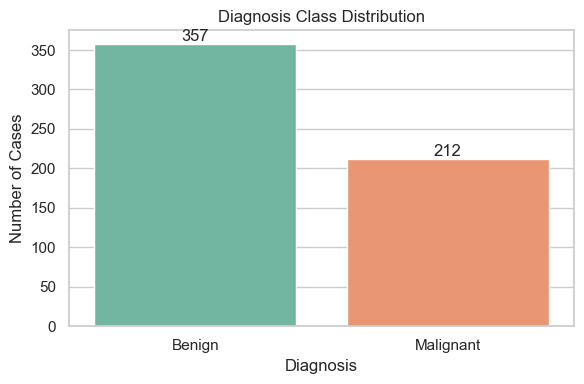

In [5]:
# 5. VISUALIZE CLASS DISTRIBUTION
class_counts = y.map({0: 'Benign', 1: 'Malignant'}).value_counts()

plt.figure(figsize=(6, 4))
ax = sns.barplot(x=class_counts.index, y=class_counts.values, hue=class_counts.index, legend=False)
for container in ax.containers:
    ax.bar_label(container)
plt.title('Diagnosis Class Distribution')
plt.xlabel('Diagnosis')
plt.ylabel('Number of Cases')
plt.tight_layout()
plt.show()

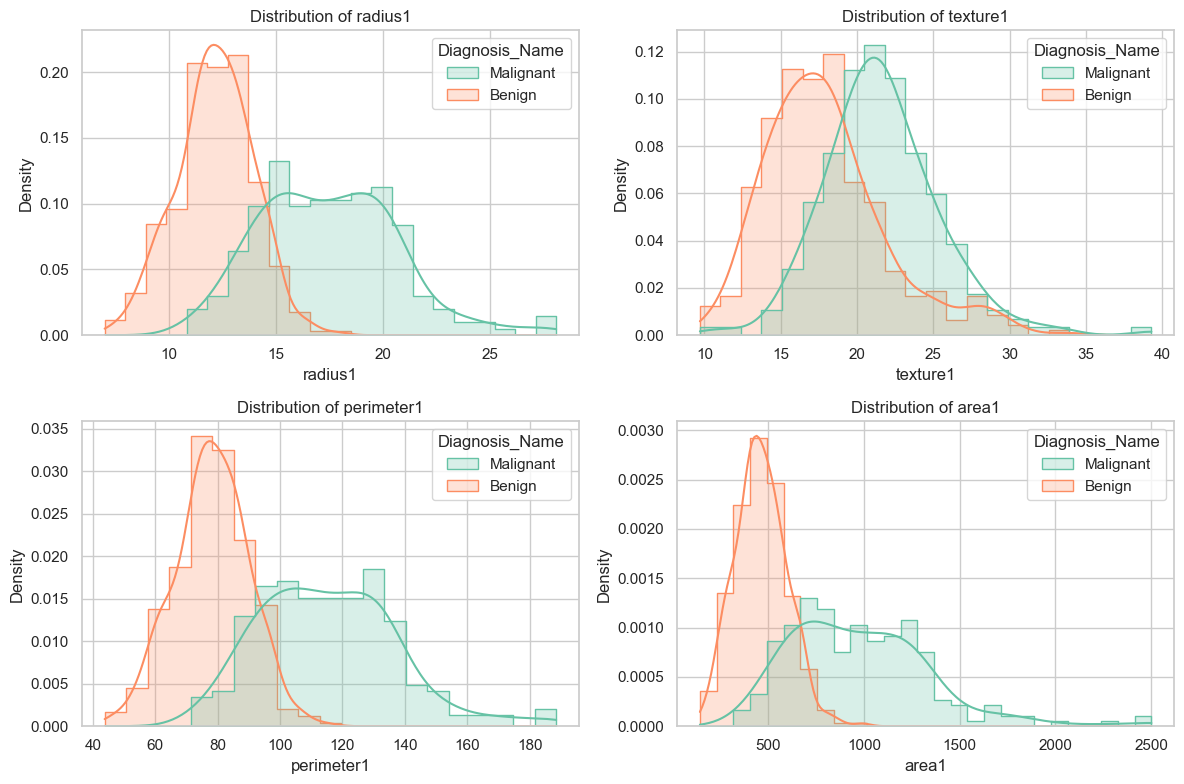

In [6]:
# 6. VISUALIZE REPRESENTATIVE FEATURE DISTRIBUTIONS
plot_df = df.assign(Diagnosis_Name=y.map({0: 'Benign', 1: 'Malignant'}))
selected_features = ['radius1', 'texture1', 'perimeter1', 'area1']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for feature, ax in zip(selected_features, axes.ravel()):
    sns.histplot(
        data=plot_df, x=feature, hue='Diagnosis_Name',
        kde=True, element='step', stat='density', common_norm=False, ax=ax
    )
    ax.set_title(f'Distribution of {feature}')
plt.tight_layout()
plt.show()

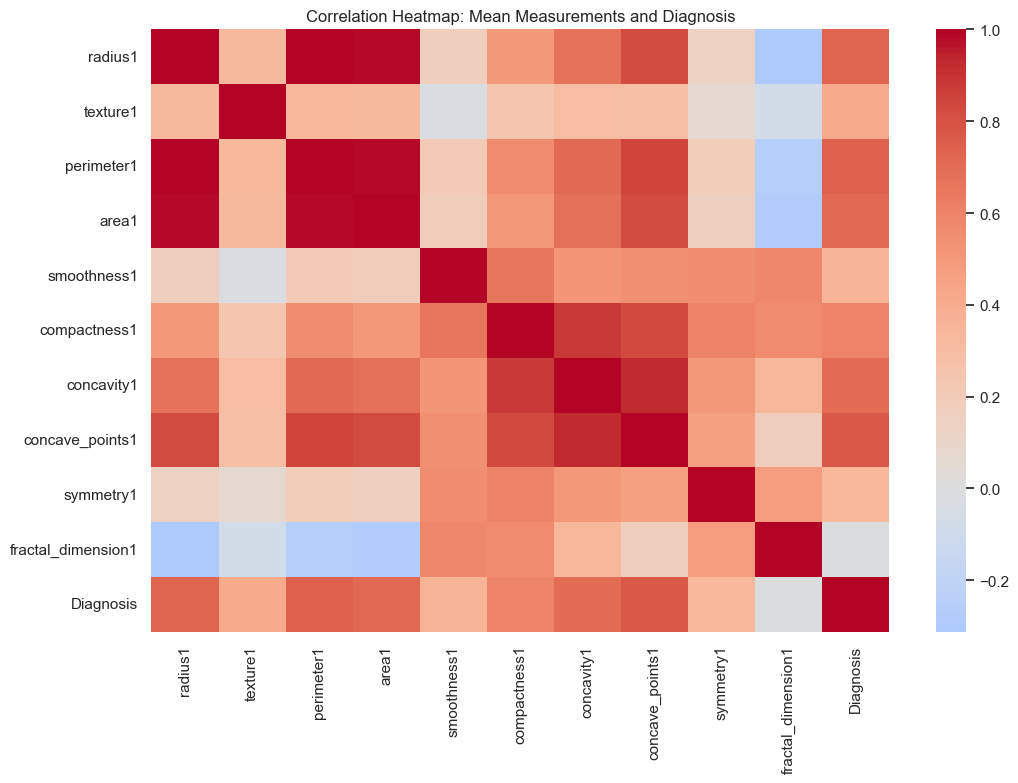

In [7]:
# 7. VISUALIZE CORRELATIONS AMONG SELECTED FEATURES
correlation_features = [
    'radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1',
    'compactness1', 'concavity1', 'concave_points1', 'symmetry1',
    'fractal_dimension1', 'Diagnosis'
]

plt.figure(figsize=(11, 8))
sns.heatmap(df[correlation_features].corr(), cmap='coolwarm', center=0, annot=False)
plt.title('Correlation Heatmap: Mean Measurements and Diagnosis')
plt.tight_layout()
plt.show()

In [8]:
# 8. TRAIN-TEST SPLIT AND FEATURE SCALING
# Stratification preserves the benign/malignant ratio in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# Fit the scaler only on training data to prevent data leakage.
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X.columns, index=X_test.index
)

print('Training set:', X_train_scaled.shape)
print('Testing set:', X_test_scaled.shape)
print('Training class proportions:\n', y_train.value_counts(normalize=True).sort_index())

Training set: (455, 30)
Testing set: (114, 30)
Training class proportions:
 Diagnosis
0    0.626374
1    0.373626
Name: proportion, dtype: float64


In [9]:
# 9. IMPLEMENT GAUSSIAN NAIVE BAYES
# GaussianNB is appropriate because the predictors are continuous values.
model = GaussianNB()
model.fit(X_train_scaled, y_train)

# Predict classes and probabilities for the unseen test set.
y_pred = model.predict(X_test_scaled)
y_proba = model.predict_proba(X_test_scaled)[:, 1]

comparison = pd.DataFrame({
    'Actual': y_test.map({0: 'Benign', 1: 'Malignant'}),
    'Predicted': pd.Series(y_pred, index=y_test.index).map({0: 'Benign', 1: 'Malignant'}),
    'P(Malignant)': y_proba
})
display(comparison.head(10))

,Actual,Predicted,P(Malignant)
120,Benign,Benign,2.604688e-16
250,Malignant,Malignant,1.000000e+00
375,Benign,Benign,2.786427e-02
99,Malignant,Benign,2.364457e-02
455,Benign,Benign,9.812227e-12
318,Benign,Malignant,9.623494e-01
39,Malignant,Malignant,9.591122e-01
371,Benign,Benign,1.400466e-12
98,Benign,Benign,5.488002e-17
502,Benign,Benign,9.408642e-13


In [10]:
# 10. EVALUATE THE MODEL
metrics = pd.Series({
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall (Sensitivity)': recall_score(y_test, y_pred),
    'F1-score': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_proba)
}).round(4)

print('Evaluation Metrics:\n', metrics)
print('\nConfusion Matrix:\n', confusion_matrix(y_test, y_pred))
print('\nClassification Report:\n')
print(classification_report(
    y_test, y_pred, target_names=['Benign', 'Malignant'], digits=4
))

Evaluation Metrics:
 Accuracy                0.9211
Precision               0.9231
Recall (Sensitivity)    0.8571
F1-score                0.8889
ROC-AUC                 0.9891
dtype: float64

Confusion Matrix:
 [[69  3]
 [ 6 36]]

Classification Report:

              precision    recall  f1-score   support

      Benign     0.9200    0.9583    0.9388        72
   Malignant     0.9231    0.8571    0.8889        42

    accuracy                         0.9211       114
   macro avg     0.9215    0.9077    0.9138       114
weighted avg     0.9211    0.9211    0.9204       114



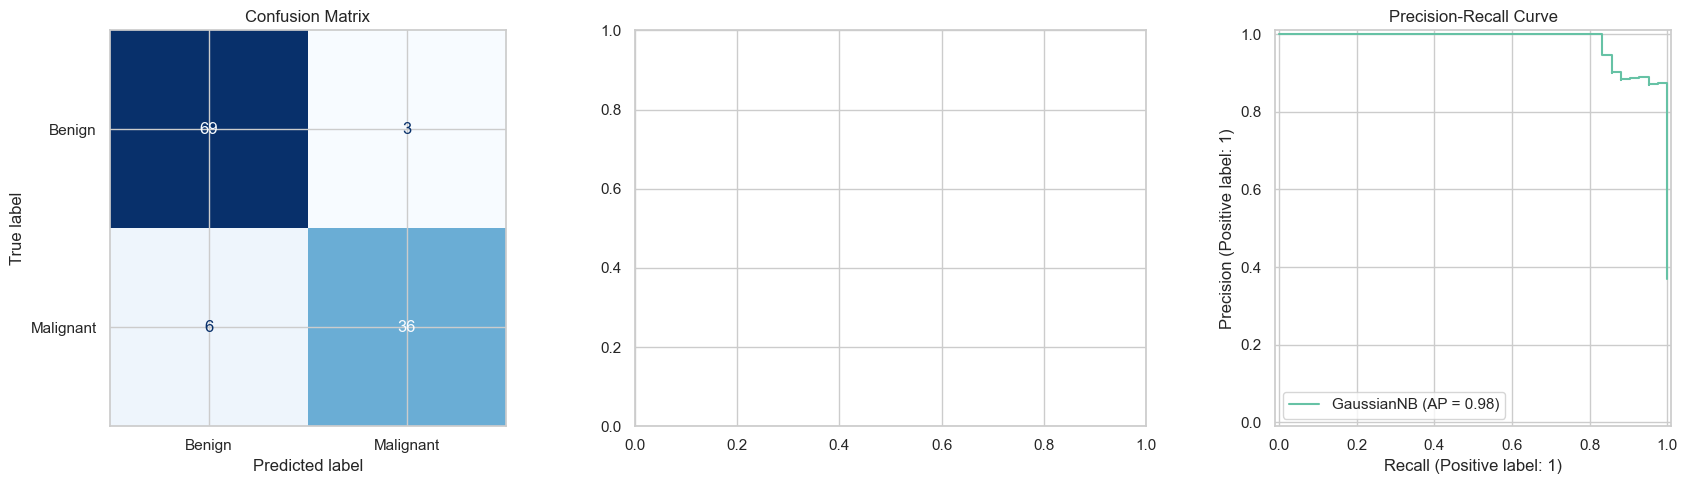

In [11]:
# 11. VISUALIZE MODEL PERFORMANCE
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=['Benign', 'Malignant'],
    cmap='Blues', colorbar=False, ax=axes[0]
)
axes[0].set_title('Confusion Matrix')

PrecisionRecallDisplay.from_predictions(
    y_test, y_proba, name='GaussianNB', ax=axes[2]
)
axes[2].set_title('Precision-Recall Curve')

plt.tight_layout()
plt.show()